# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [6]:
!pip install matplotlib seaborn plotly==6.1.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 83.1 MB/s eta 0:00:00
  Attempting uninstall: plotly
    Found existing installation: plotly 5.24.1
    Uninstalling plotly-5.24.1:
      Successfully uninstalled plotly-5.24.1


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('yulu_rental.csv')

In [8]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [9]:
df

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,2012-12-19,19,51,2,Wednesday,2012,12,19
2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,2012-12-19,19,51,2,Wednesday,2012,12,20
2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,2012-12-19,19,51,2,Wednesday,2012,12,21


10886 rows × 19 columns

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 10886 entries, 2011-01-01 00:00:00 to 2012-12-19 23:00:00
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   season       10886 non-null  int64  
 1   holiday      10886 non-null  int64  
 2   workingday   10886 non-null  int64  
 3   weather      10886 non-null  int64  
 4   temp         10886 non-null  float64
 5   atemp        10886 non-null  float64
 6   humidity     10886 non-null  int64  
 7   windspeed    10886 non-null  float64
 8   casual       10886 non-null  int64  
 9   registered   10886 non-null  int64  
 10  count        10886 non-null  int64  
 11  date         10886 non-null  object 
 12  day          10886 non-null  int32  
 13  week         10886 non-null  UInt32 
 14  weekday_num  10886 non-null  int32  
 15  weekday      10886 non-null  object 
 16  year         10886 non-null  int32  
 17  month        10886 non-null  int32  
 18  hour       

**Оригінальний датасет містить:**
10 886 рядків х 12 колонок, розмір - 1020.7 KB

**Після підготовки даних:** 10 886 рядків × 19 колонок (через додаткові колонки), розмір 1,4+МВ

Порожніх значень немає (усе non-Null). Деталізація на рівні рядку - година, видно із datetime. Часовий проміжок: 01.01.2011 - 19.12.2012

In [11]:
# Сезони Індії за місяцями
# 1 = Winter, 2 = Summer, 3 = Monsoon, 4 = Post-Monsoon

season_num_map_india = {
    12: 1, 1: 1, 2: 1,          # Winter
    3: 2, 4: 2, 5: 2,           # Summer
    6: 3, 7: 3, 8: 3, 9: 3,     # Monsoon
    10: 4, 11: 4                # Post-Monsoon
}

df['weather_season_india'] = df['month'].map(season_num_map_india)

# Текстові назви сезонів
season_name_map_india = {
    1: 'Winter',
    2: 'Summer',
    3: 'Monsoon',
    4: 'Post-Monsoon'
}

df['weather_season_india_name'] = df['weather_season_india'].map(season_name_map_india)

df[['month', 'weather_season_india', 'weather_season_india_name']].head(3)

,month,weather_season_india,weather_season_india_name
datetime,,,
2011-01-01 00:00:00,1,1,Winter
2011-01-01 01:00:00,1,1,Winter
2011-01-01 02:00:00,1,1,Winter


In [12]:
df['weather_season_india_name'].value_counts()

,count
weather_season_india_name,
Monsoon,3645
Summer,2722
Winter,2697
Post-Monsoon,1822


## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


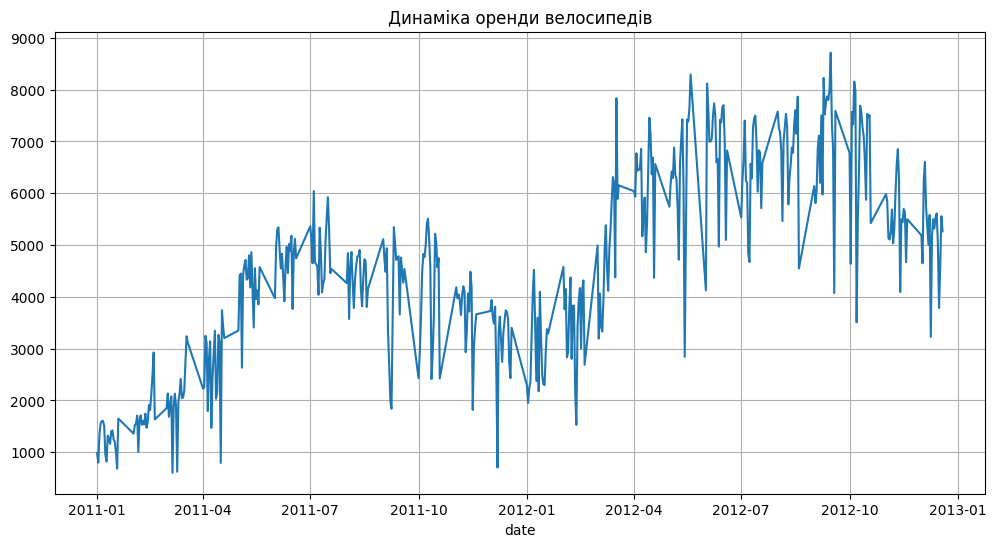

In [13]:
df.groupby('date')['count'].sum().plot(
    figsize=(12, 6),
    title="Динаміка оренди велосипедів",
    grid=True
);

1. **Коливання та згладжування даних:**
Різкі стрибки на графіку пояснюються щоденними чинниками, такими як погода, вихідні чи святкові дні. Щоб прибрати цей «шум» та отримати наочнішу картину, краще застосувати ковзне середнє (скажімо, з тижневим інтервалом).
2. **Динаміка та порівняння:**
Чітко простежується збільшення попиту влітку та його зменшення взимку. Водночас у 2012 році показники були стабільно вищими, ніж за той самий проміжок часу попереднього, 2011 року.
3. **Сезонність:**
Наявність сезонних коливань підтверджено: найвищі показники спостерігаються в середині року, а найнижчі — у зимовий період.
4. **Відхилення від тренду:**
Зафіксовано окремі аномалії. Ймовірно, різкі злети або падіння попиту зумовлені погодними форс-мажорами, святами чи місцевими подіями.


## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

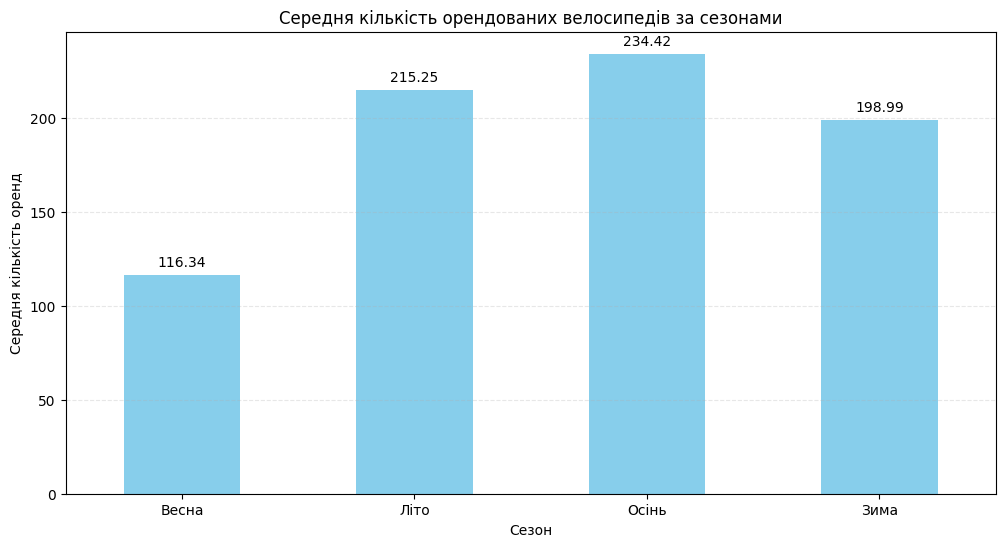

In [15]:
season_names = {1: 'Весна', 2: 'Літо', 3: 'Осінь', 4: 'Зима'}

q_rent = df.groupby('season')['count'].mean()
q_rent.index = q_rent.index.map(season_names)

ax = q_rent.plot.bar(
    figsize=(12, 6),
    color='skyblue',
    rot=0,
)
ax.set_title('Середня кількість орендованих велосипедів за сезонами')
ax.set_xlabel('Сезон')
ax.set_ylabel('Середня кількість оренд')
ax.grid(axis='y', linestyle='--', alpha=0.3)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.show()

1. **В який квартал найбільша середня кількість оренди велосипедів?**
Найвищий середній показник оренди припадає на 3-й квартал (позначений як «Осінь»). У наданій вибірці цей часовий відрізок охоплює найбільш теплі місяці року (з липня по вересень).
2. **Як ви можете пояснити таку сезонну закономірність?**
Головною причиною є погодні умови. Протягом 2-го та 3-го кварталів утримується найкомфортніша погода для велопоїздок. Водночас у 1-му кварталі (зимовий період та рання весна) через низьку температуру попит суттєво падає.
3. **У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?**

In [22]:
diff = q_rent.max() / q_rent.min()
print(f"Різниця складає {diff:.2f} рази")

Різниця складає 2.01 рази


## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


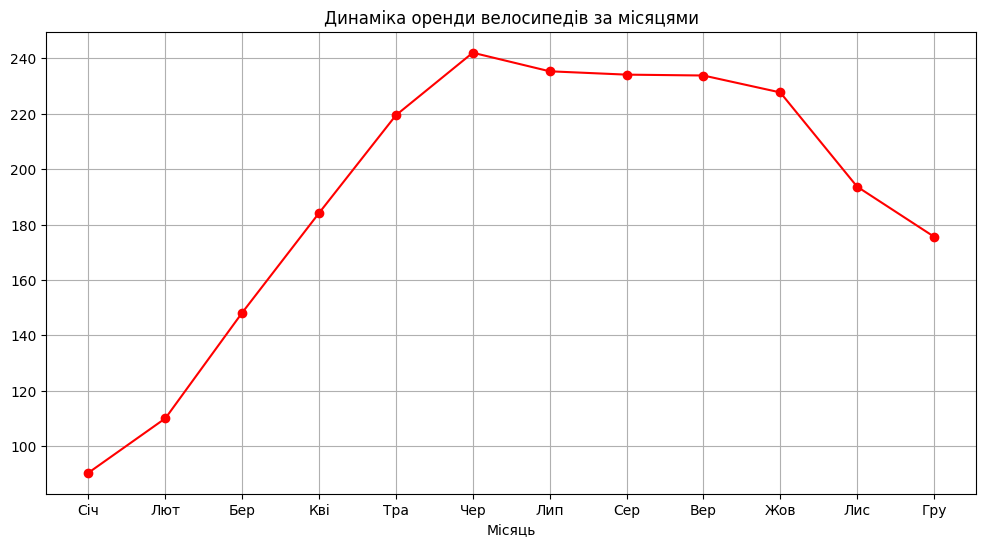

In [17]:
month_avg = df.groupby('month')['count'].mean()

ax = month_avg.plot(
    figsize=(12, 6),
    title="Динаміка оренди велосипедів за місяцями",
    grid=True,
    marker='o',
    color='red',
    xlabel='Місяць'
);

# 12 поділок по осі X
ax.set_xticks(range(1,13))

# Підписи місяців
ax.set_xticklabels(
    ['Січ', 'Лют', 'Бер', 'Кві', 'Тра', 'Чер', 'Лип', 'Сер', 'Вер', 'Жов', 'Лис', 'Гру'],
    rotation=0
)

plt.show()

1. **Пікові та низькі періоди:**
Найбільший попит зафіксовано в червні, хоча загалом активний період триває аж до жовтня. Найнижчий рівень залученості спостерігається у січні.
2. **Загальний тренд:**
На діаграмі чітко видно вже знайому закономірність: у теплі місяці кількість орендованих велосипедів суттєво зростає.
3. **Залежність від погоди:**
Отримані дані доводять, що цей бізнес є сезонним — гарна та сприятлива погода безпосередньо сприяє збільшенню кількості бронювань.

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

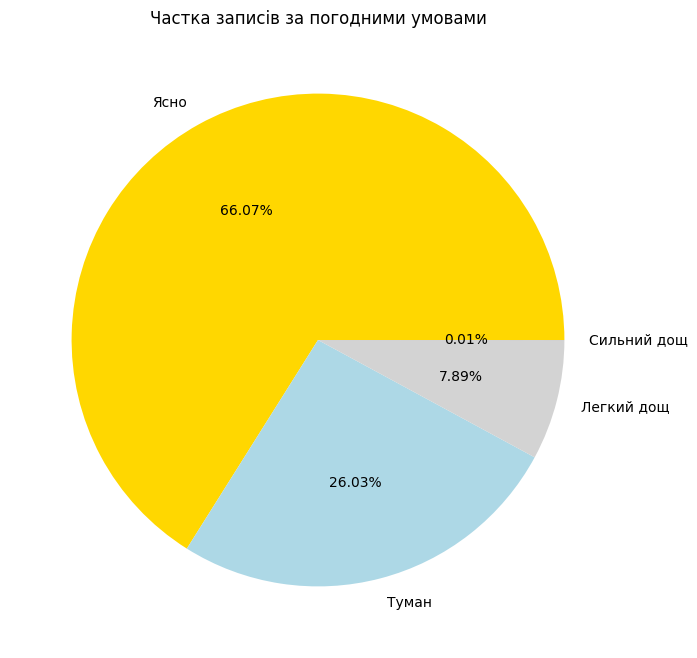

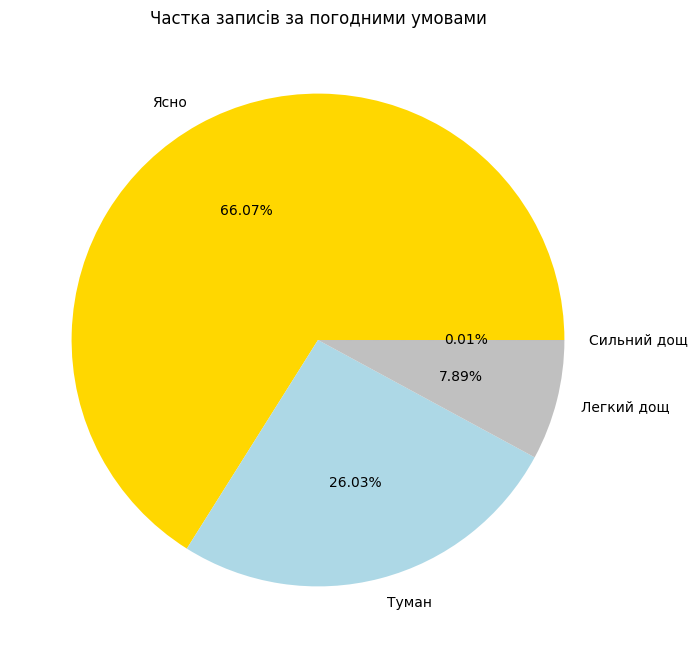

In [18]:
weather_data = df['weather'].value_counts()
weather_type = {1: 'Ясно', 2: 'Туман', 3: 'Легкий дощ', 4: 'Сильний дощ'}
weather_data.index = weather_data.index.map(weather_type)

weather_data.plot.pie(
    figsize=(8, 8),
    autopct='%1.2f%%',
    title='Частка записів за погодними умовами',
    ylabel='',
    colors=['gold', 'lightblue', 'silver', 'grey'],
)

plt.show()

1. **Яка погода переважає в датасеті?**
Найчастіше фіксується сонячна та ясна погода (66.07%), що становить понад дві третини від загального обсягу даних.
2. **Чи є дні із сильним дощем? Яка їх частка?**
Так, подібні дні присутні, проте їхня кількість мізерна — лише 0.01%. Це свідчить про те, що екстремальні опади траплялися вкрай рідко за весь час спостережень.
3. **Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?**
Метеоумови відіграють вирішальну роль. Оскільки дві третини часу утримується хороша погода, сервіс демонструє найвищу активність саме в сприятливі дні. Погіршення умов до туману чи дощу призводить до різкого спаду попиту через незручність та ризики для поїздок, тоді як сильна негода (0.01%) практично повністю зупиняє використання оренди.

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

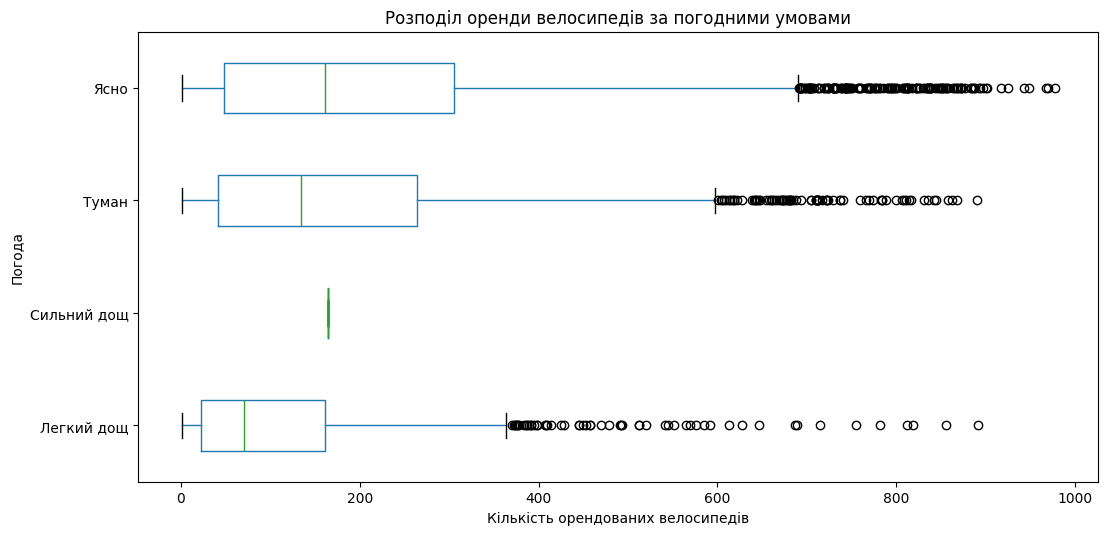

In [19]:
weather_type = {1: 'Ясно', 2: 'Туман', 3: 'Легкий дощ', 4: 'Сильний дощ'}

df_plot = df.copy()
df_plot['weather_name'] = df_plot['weather'].map(weather_type)

ax_box = df_plot.boxplot(
    column='count',
    by='weather_name',
    vert=False,
    figsize=(12, 6),
    grid=False
)

plt.title('Розподіл оренди велосипедів за погодними умовами')
plt.suptitle('')
plt.xlabel('Кількість орендованих велосипедів')
plt.ylabel('Погода')

plt.show()

1. **При якій погоді найбільший розкид у кількості оренди?**
Найширший діапазон варіації значень спостерігається за умови «Ясно».
2. **Чи є викиди (outliers) в даних? При якій погоді?**
Так, аномальні значення зафіксовані практично для кожного типу погоди. Найбільша їх кількість зосереджена в категоріях «Ясно» та «Туман».
3. **При якій погоді медіанне значення оренди найвище?**
Найвищий показник медіани припадає на сонячну погоду («Ясно»). Це свідчить про те, що саме за сприятливих метеоумов середній (типовий) рівень оренди досягає максимумів порівняно з іншими станами погоди.

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

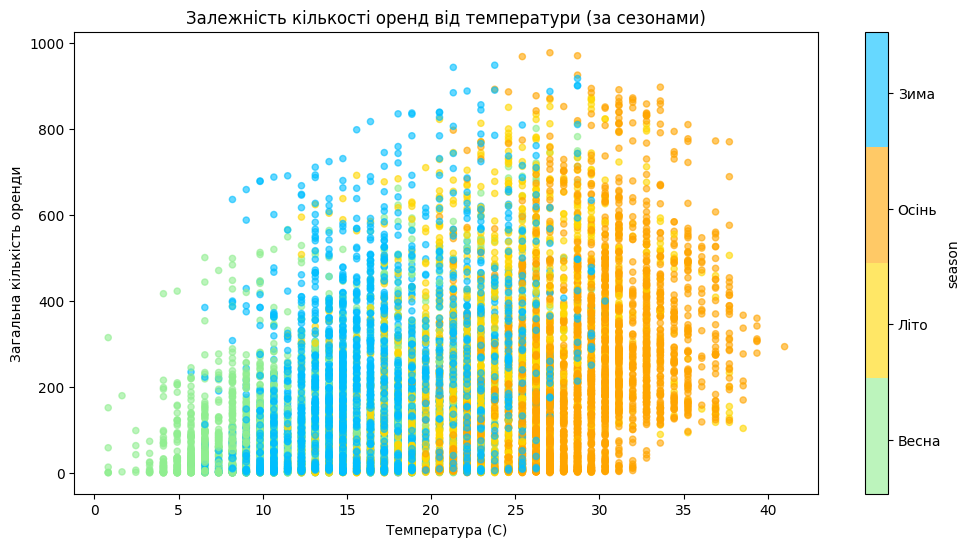

In [20]:
from matplotlib.colors import ListedColormap

my_colors = ['lightgreen', 'gold', 'orange', 'deepskyblue']
my_cmap = ListedColormap(my_colors)

ax_scatter = df.plot.scatter(
    x='temp',
    y='count',
    c='season',
    cmap=my_cmap,
    alpha=0.6,
    figsize=(12, 6),
    sharex=False
)

plt.title('Залежність кількості оренд від температури (за сезонами)')
plt.xlabel('Температура (C)')
plt.ylabel('Загальна кількість оренди')

cbar = ax_scatter.collections[0].colorbar
cbar.set_ticks([1.35, 2.1, 2.85, 3.6])
cbar.set_ticklabels(['Весна', 'Літо', 'Осінь', 'Зима'])

plt.show()

**Чи є зв'язок між температурою та кількістю оренди? Який?**
Так, графік демонструє пряму лінійну кореляцію між цими параметрами: із підвищенням температури повітря зростає й обсяг оренди. Найбільша активність користувачів припадає на температурний діапазон від 25°C до 35°C. Цей фактор є ключовим для попиту, оскільки в теплі дні сервісом користуються значно частіше, ніж у холодні.

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

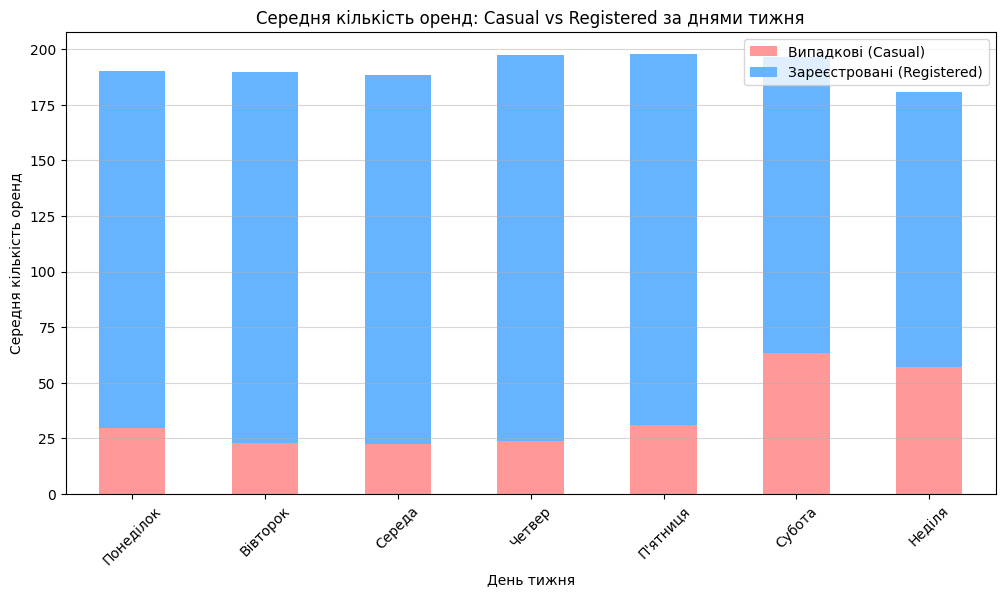

In [21]:
day_names = {0: 'Понеділок', 1: 'Вівторок', 2: 'Середа', 3: 'Четвер', 4: "П'ятниця", 5: 'Субота', 6: 'Неділя'}
user_stats = df.groupby('weekday_num')[['casual', 'registered']].mean()
user_stats.index = user_stats.index.map(day_names)

ax_bars = user_stats.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=['#ff9999', '#66b3ff'],
    rot=45
)

# 4. Налаштування
plt.title('Середня кількість оренд: Casual vs Registered за днями тижня')
plt.xlabel('День тижня')
plt.ylabel('Середня кількість оренд')
plt.legend(['Випадкові (Casual)', 'Зареєстровані (Registered)'])
plt.grid(axis='y', alpha=0.5)

plt.show()

1. **В які дні тижня більше оренд від зареєстрованих користувачів?**
Пікові показники оренди серед зареєстрованих користувачів припадають на робочі дні (з понеділка по п'ятницю).
2. **Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?**
Постійні (зареєстровані) користувачі — це здебільшого місцеві мешканці, які обирають велосипеди як регулярний транспорт для доїзду на роботу чи навчання. Через це їхня залученість є стабільно високою впродовж робочого тижня.
Разові користувачі (Casual), навпаки, є переважно туристами або відпочивальниками. Їхній попит суттєво підвищується у вихідні (суботу та неділю), коли зростає потреба в дозвіллі та прогулянках.